# Customer Segmentation Analysis Using Python

## Project Overview

This project analyzes customer purchasing behavior using
the Online Retail dataset.

The goal is to identify meaningful customer segments using
Recency, Frequency, and Monetary (RFM) analysis and
K-Means clustering.

## Objectives

- Inspect and clean the retail transaction dataset.
- Perform exploratory data analysis.
- Calculate customer-level RFM metrics.
- Identify customer segments using K-Means clustering.
- Visualize purchasing patterns.
- Develop actionable business recommendations.

## Tools and Technologies

- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- Jupyter Notebook

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the Online Retail dataset
df = pd.read_excel("../data/Online Retail.xlsx")

# Display the first five rows
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [18]:
# Dataset dimensions
print("Dataset Shape:", df.shape)

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

# Dataset information
print("\nDataset Information:")
df.info()

# Descriptive statistics
print("\nDescriptive Statistics:")
display(df.describe(include="all").T)

Dataset Shape: (541909, 8)

Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB

Descriptive Statistics:


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [19]:
# Missing values
print("Missing Values:")
print(df.isnull().sum())

# Duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# Unique customers
print("\nUnique Customers:", df["CustomerID"].nunique())

# Unique invoices
print("Unique Invoices:", df["InvoiceNo"].nunique())

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate Rows: 5268

Unique Customers: 4372
Unique Invoices: 25900


## Data Cleaning and Preparation

The original dataset contains 541,909 transaction records
and 8 columns.

Initial inspection identified missing customer IDs,
missing product descriptions, and duplicate records.

The cleaning process will:
- Remove exact duplicate records.
- Exclude transactions without customer IDs.
- Identify cancelled invoices.
- Investigate invalid quantities and prices.
- Convert data into appropriate formats.
- Prepare a clean dataset for customer-level RFM analysis.

The original dataset will remain unchanged.

In [20]:
# Preserve the original dataset
df_raw = df.copy()

# Create a working copy for cleaning
df_clean = df_raw.copy()

print("Original dataset shape:", df_raw.shape)
print("Working dataset shape:", df_clean.shape)

Original dataset shape: (541909, 8)
Working dataset shape: (541909, 8)


In [21]:
# Reset the working dataset
df_clean = df_raw.copy()

# Count exact duplicate rows before removal
duplicates_before = df_clean.duplicated().sum()

# Remove exact duplicate rows
df_clean = df_clean.drop_duplicates().copy()

# Verify the results
print("Original dataset rows:", len(df_raw))
print("Duplicates identified:", duplicates_before)
print("Rows after duplicate removal:", len(df_clean))
print("Duplicates remaining:", df_clean.duplicated().sum())
print("Rows removed:", len(df_raw) - len(df_clean))

Original dataset rows: 541909
Duplicates identified: 5268
Rows after duplicate removal: 536641
Duplicates remaining: 0
Rows removed: 5268


### Identify Cancelled Transactions and Invalid Values

The Online Retail dataset contains cancelled invoices, negative quantities,
and non-positive unit prices.

These records are examined before cleaning to understand their impact
on transaction-level analysis.

Negative quantities may represent product returns, while cancelled
invoices require separate investigation.

The original dataset is preserved to ensure that cleaning decisions
can be reviewed and reproduced.

In [22]:
# Identify cancelled invoices
cancelled_mask = (
    df_clean["InvoiceNo"]
    .astype(str)
    .str.startswith("C")
)

print("Cancelled invoice rows:", cancelled_mask.sum())

# Examine negative quantities
print(
    "Rows with negative quantity:",
    (df_clean["Quantity"] < 0).sum()
)

# Examine zero quantities
print(
    "Rows with zero quantity:",
    (df_clean["Quantity"] == 0).sum()
)

# Examine invalid prices
print(
    "Rows with zero or negative unit price:",
    (df_clean["UnitPrice"] <= 0).sum()
)

Cancelled invoice rows: 9251
Rows with negative quantity: 10587
Rows with zero quantity: 0
Rows with zero or negative unit price: 2512


In [23]:
# Record row count before removing missing customer IDs
rows_before_customer_filter = len(df_clean)

# Remove transactions without customer IDs
df_clean = df_clean.dropna(subset=["CustomerID"]).copy()

print(
    "Rows removed due to missing CustomerID:",
    rows_before_customer_filter - len(df_clean)
)

print("Rows remaining:", len(df_clean))
print("Missing CustomerIDs remaining:", df_clean["CustomerID"].isna().sum())

Rows removed due to missing CustomerID: 135037
Rows remaining: 401604
Missing CustomerIDs remaining: 0


In [24]:
# Convert CustomerID to integer after removing missing values
df_clean["CustomerID"] = df_clean["CustomerID"].astype("int64")

# Ensure InvoiceDate is datetime
df_clean["InvoiceDate"] = pd.to_datetime(
    df_clean["InvoiceDate"],
    errors="coerce"
)

# Remove records with invalid dates
df_clean = df_clean.dropna(subset=["InvoiceDate"]).copy()

# Confirm data types
df_clean.info()

<class 'pandas.DataFrame'>
Index: 401604 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    401604 non-null  object        
 1   StockCode    401604 non-null  object        
 2   Description  401604 non-null  object        
 3   Quantity     401604 non-null  int64         
 4   InvoiceDate  401604 non-null  datetime64[us]
 5   UnitPrice    401604 non-null  float64       
 6   CustomerID   401604 non-null  int64         
 7   Country      401604 non-null  str           
dtypes: datetime64[us](1), float64(1), int64(2), object(3), str(1)
memory usage: 27.6+ MB


In [25]:
from pathlib import Path

# Create the processed-data folder if it doesn't exist
processed_dir = Path("../processed")
processed_dir.mkdir(parents=True, exist_ok=True)

# Save the cleaned data
df_clean.to_csv(
    processed_dir / "online_retail_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully.")
print("Cleaned dataset shape:", df_clean.shape)

Cleaned dataset saved successfully.
Cleaned dataset shape: (401604, 8)


## Transaction Filtering and Revenue Analysis

In this section, the cleaned retail dataset is prepared for customer
segmentation.

The analysis will:
- Identify and exclude cancelled invoices.
- Exclude transactions with non-positive quantities.
- Exclude transactions with non-positive unit prices.
- Calculate revenue for each transaction.
- Prepare the dataset for Recency, Frequency, and Monetary (RFM) analysis.

In [26]:
# Create a separate dataset for transaction analysis

df_analysis = df_clean.copy()

# Check the dataset before filtering

print("Rows before filtering:", len(df_analysis))
print("Columns:", df_analysis.shape[1])

Rows before filtering: 401604
Columns: 8


In [27]:
# Identify cancelled invoices

cancelled_mask = (
    df_analysis["InvoiceNo"]
    .astype(str)
    .str.strip()
    .str.startswith("C", na=False)
)

print("Cancelled invoice rows:", cancelled_mask.sum())

# Remove cancelled invoices

df_analysis = df_analysis.loc[~cancelled_mask].copy()

# Remove transactions with non-positive quantities

df_analysis = df_analysis.loc[
    df_analysis["Quantity"] > 0
].copy()

# Remove transactions with non-positive prices

df_analysis = df_analysis.loc[
    df_analysis["UnitPrice"] > 0
].copy()

# Display the results

print("\nRows after filtering:", len(df_analysis))
print("Missing CustomerIDs:", df_analysis["CustomerID"].isna().sum())
print("Invalid quantities:", (df_analysis["Quantity"] <= 0).sum())
print("Invalid prices:", (df_analysis["UnitPrice"] <= 0).sum())

Cancelled invoice rows: 8872

Rows after filtering: 392692
Missing CustomerIDs: 0
Invalid quantities: 0
Invalid prices: 0


In [28]:
# Calculate revenue for each transaction

df_analysis["Revenue"] = (
    df_analysis["Quantity"] * df_analysis["UnitPrice"]
)

# Display the first five transactions

display(df_analysis.head())

# Check the revenue column

print("\nRevenue Statistics:")
print(df_analysis["Revenue"].describe())

# Calculate total revenue

print(
    "\nTotal Revenue:",
    round(df_analysis["Revenue"].sum(), 2)
)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34



Revenue Statistics:
count    392692.000000
mean         22.631500
std         311.099224
min           0.001000
25%           4.950000
50%          12.450000
75%          19.800000
max      168469.600000
Name: Revenue, dtype: float64

Total Revenue: 8887208.89


## Customer-Level RFM Analysis

This section summarizes customer purchasing behaviour using Recency, Frequency, and Monetary (RFM) metrics.

- Recency measures the number of days since a customer's most recent purchase.
- Frequency measures the number of distinct invoices associated with a customer.
- Monetary measures the total revenue generated by each customer.

The resulting customer-level dataset will be used for customer segmentation.

In [29]:
# Create a copy for customer-level RFM analysis

df_rfm = df_analysis.copy()

# Define the reference date for recency calculation

reference_date = df_rfm["InvoiceDate"].max() + pd.Timedelta(days=1)

print("Reference Date:", reference_date)
print("Transactions available:", len(df_rfm))
print("Unique customers:", df_rfm["CustomerID"].nunique())

Reference Date: 2011-12-10 12:50:00
Transactions available: 392692
Unique customers: 4338


In [30]:
# Calculate RFM metrics for each customer

rfm = df_rfm.groupby("CustomerID").agg(
    Recency=(
        "InvoiceDate",
        lambda x: (reference_date - x.max()).days
    ),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum")
).reset_index()

# Display the first five customers

display(rfm.head())

# Check the dimensions of the RFM dataset

print("\nRFM Dataset Shape:", rfm.shape)

# Display summary statistics

print("\nRFM Summary Statistics:")
display(rfm[["Recency", "Frequency", "Monetary"]].describe().round(2))

# Check for missing values

print("\nMissing Values:")
print(rfm.isnull().sum())

,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,2,7,4310.00
2,12348,75,4,1797.24
3,12349,19,1,1757.55
4,12350,310,1,334.40



RFM Dataset Shape: (4338, 4)

RFM Summary Statistics:


,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,92.54,4.27,2048.69
std,100.01,7.70,8985.23
min,1.00,1.00,3.75
25%,18.00,1.00,306.48
50%,51.00,2.00,668.57
75%,142.00,5.00,1660.60
max,374.00,209.00,280206.02



Missing Values:
CustomerID    0
Recency       0
Frequency     0
Monetary      0
dtype: int64


## Exploratory Data Analysis of RFM Metrics

This section explores the distribution of customer Recency, Frequency, and Monetary values.

Histograms will help identify purchasing patterns, variations in customer activity, and potential outliers before applying K-Means clustering.

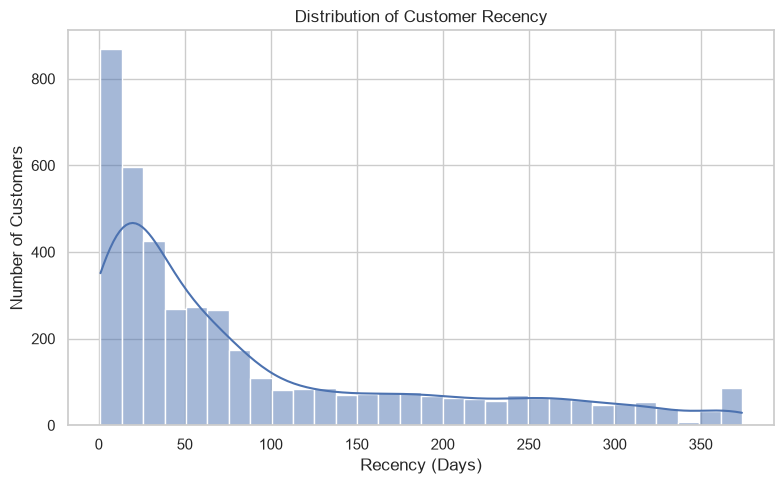

<Figure size 640x480 with 0 Axes>

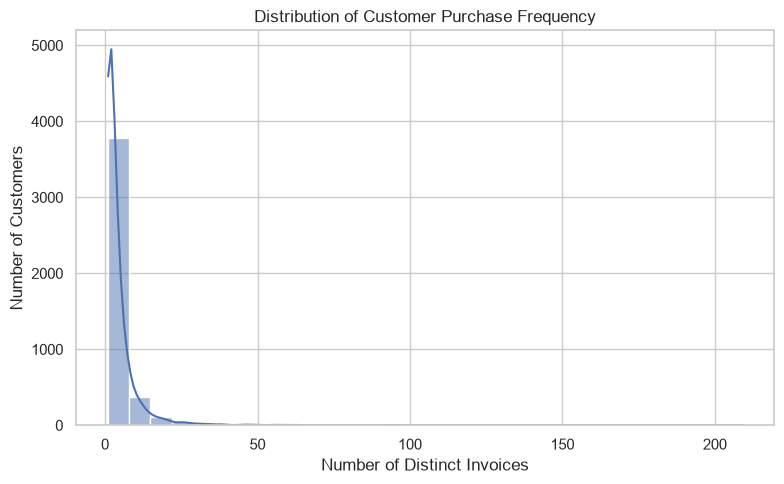

<Figure size 640x480 with 0 Axes>

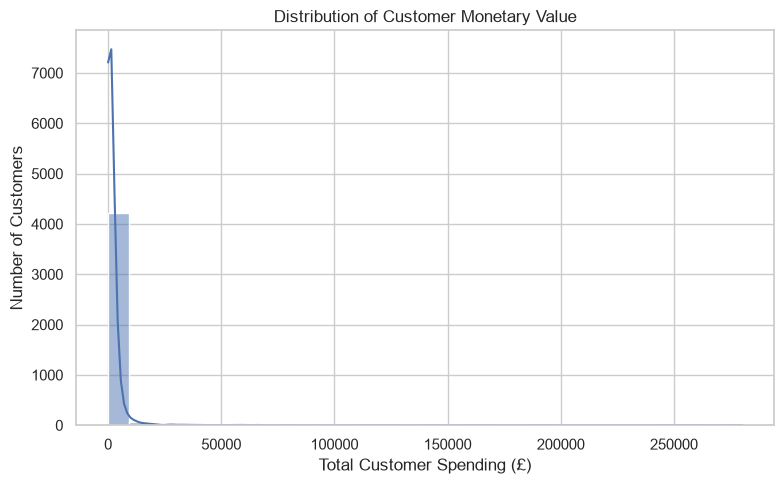

<Figure size 640x480 with 0 Axes>

In [33]:
# Visualize the distributions of RFM metrics

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Recency distribution

plt.figure(figsize=(8, 5))
sns.histplot(data=rfm, x="Recency", bins=30, kde=True)
plt.title("Distribution of Customer Recency")
plt.xlabel("Recency (Days)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

plt.savefig("../images/recency_distribution.png",
            dpi = 300, bbox_inches = "tight")

# Frequency distribution

plt.figure(figsize=(8, 5))
sns.histplot(data=rfm, x="Frequency", bins=30, kde=True)
plt.title("Distribution of Customer Purchase Frequency")
plt.xlabel("Number of Distinct Invoices")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

plt.savefig("../images/frequency_distribution.png",
            dpi = 300, bbox_inches = "tight")

# Monetary distribution

plt.figure(figsize=(8, 5))
sns.histplot(data=rfm, x="Monetary", bins=30, kde=True)
plt.title("Distribution of Customer Monetary Value")
plt.xlabel("Total Customer Spending (£)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

plt.savefig("../images/monetary_distribution.png",
            dpi = 300, bbox_inches = "tight")

## RFM Data Preparation for K-Means Clustering

The RFM metrics have different numerical scales and distributions.

Before applying K-Means clustering, the features will be transformed to reduce the influence of extreme values and standardize their scales.

The prepared features will be used to identify groups of customers with similar purchasing behaviour.

In [32]:
# Prepare RFM features for clustering

import numpy as np
import pandas as pd

# Select the numerical RFM features
rfm_features = rfm[["Recency", "Frequency", "Monetary"]].copy()

# Apply log transformation to reduce right-skewness
rfm_log = np.log1p(rfm_features)

# Check the transformed data
print("Transformed RFM data:")
display(rfm_log.head())

print("\nSummary statistics after log transformation:")
display(rfm_log.describe())

print("\nMissing values:")
print(rfm_log.isnull().sum())

print("\nInfinite values:")
print(np.isinf(rfm_log).sum())

Transformed RFM data:


,Recency,Frequency,Monetary
0,5.789960,0.693147,11.253955
1,1.098612,2.079442,8.368925
2,4.330733,1.609438,7.494564
3,2.995732,0.693147,7.472245
4,5.739793,0.693147,5.815324



Summary statistics after log transformation:


,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,3.830734,1.345582,6.588562
std,1.340261,0.683104,1.258438
min,0.693147,0.693147,1.558145
25%,2.944439,0.693147,5.728418
50%,3.951244,1.098612,6.506636
75%,4.962845,1.791759,7.415535
max,5.926926,5.347108,12.543284



Missing values:
Recency      0
Frequency    0
Monetary     0
dtype: int64

Infinite values:
Recency      0
Frequency    0
Monetary     0
dtype: int64


## RFM Feature Scaling

The log-transformed RFM features are standardized using StandardScaler.

This ensures that Recency, Frequency, and Monetary contribute on a comparable scale when calculating distances for K-Means clustering.

In [34]:
# Import StandardScaler
from sklearn.preprocessing import StandardScaler

# Create a copy of the log-transformed RFM data
rfm_scaled_data = rfm_log.copy()

# Initialize the scaler
scaler = StandardScaler()

# Standardize the RFM features
rfm_scaled_array = scaler.fit_transform(rfm_scaled_data)

# Convert the scaled array into a DataFrame
rfm_scaled = pd.DataFrame(
    rfm_scaled_array,
    columns=["Recency", "Frequency", "Monetary"],
    index=rfm_scaled_data.index
)

# Display the first five rows
print("First five rows of scaled RFM data:")
display(rfm_scaled.head())

# Check the dataset shape
print("\nScaled dataset shape:", rfm_scaled.shape)

# Verify feature means
print("\nFeature means:")
print(rfm_scaled.mean().round(3))

# Verify feature standard deviations
print("\nFeature standard deviations:")
print(rfm_scaled.std().round(3))

First five rows of scaled RFM data:


,Recency,Frequency,Monetary
0,1.461993,-0.955214,3.707716
1,-2.038734,1.074425,1.414903
2,0.373104,0.386304,0.720024
3,-0.623086,-0.955214,0.702287
4,1.424558,-0.955214,-0.614514



Scaled dataset shape: (4338, 3)

Feature means:
Recency     -0.0
Frequency   -0.0
Monetary    -0.0
dtype: float64

Feature standard deviations:
Recency      1.0
Frequency    1.0
Monetary     1.0
dtype: float64


## Optimal Number of Clusters — Elbow Method

The Elbow Method evaluates different numbers of clusters by measuring the within-cluster sum of squares (inertia).

The inertia values are plotted against the number of clusters. The point where the reduction in inertia begins to slow down helps identify a suitable number of clusters for customer segmentation.

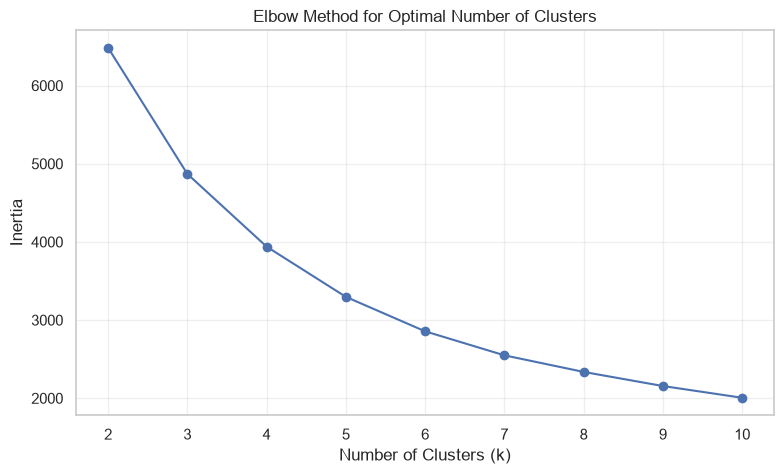

In [35]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Calculate inertia for different numbers of clusters
inertia_values = []

k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(rfm_scaled)

    inertia_values.append(kmeans.inertia_)

# Plot the Elbow Method
plt.figure(figsize=(9, 5))

plt.plot(
    list(k_values),
    inertia_values,
    marker="o"
)

plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)

# Save the chart in the images folder
plt.savefig(
    "../images/elbow_method.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## K-Means Customer Segmentation

The Elbow Method suggests that four clusters are a reasonable starting point for customer segmentation.

K-Means clustering will be applied to the standardized RFM features to group customers according to their purchasing behaviour.

The resulting clusters will be evaluated using the Silhouette Score.

In [36]:
# Import K-Means and evaluation metrics
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Set the initial number of clusters
optimal_k = 4

# Initialize the K-Means model
kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

# Fit the model and assign cluster labels
cluster_labels = kmeans.fit_predict(rfm_scaled)

# Evaluate clustering quality
sil_score = silhouette_score(rfm_scaled, cluster_labels)

# Display the results
print("Number of clusters:", optimal_k)
print("Number of customers:", len(rfm_scaled))
print("Silhouette Score:", round(sil_score, 4))

# Check the number of customers in each cluster
print("\nCustomers in each cluster:")
print(
    pd.Series(cluster_labels, name="Cluster")
    .value_counts()
    .sort_index()
)

Number of clusters: 4
Number of customers: 4338
Silhouette Score: 0.3375

Customers in each cluster:
Cluster
0     713
1    1622
2     837
3    1166
Name: count, dtype: int64


## Customer Cluster Assignment

Each customer is assigned to a cluster based on their standardized RFM characteristics.

The cluster labels are added to the original RFM dataset so that customer groups can be analysed and interpreted.

In [37]:
# Create a copy of the original RFM dataset
rfm_segmented = rfm.copy()

# Add cluster assignments
rfm_segmented["Cluster"] = cluster_labels

# Display sample customer records
print("Sample customer segments:")
display(rfm_segmented.head())

# Display the number of customers in each cluster
print("\nCluster distribution:")
print(
    rfm_segmented["Cluster"]
    .value_counts()
    .sort_index()
)

# Verify the dataset shape
print("\nSegmented dataset shape:", rfm_segmented.shape)

Sample customer segments:


,CustomerID,Recency,Frequency,Monetary,Cluster
0,12346,326,1,77183.60,3
1,12347,2,7,4310.00,0
2,12348,75,4,1797.24,3
3,12349,19,1,1757.55,2
4,12350,310,1,334.40,1



Cluster distribution:
Cluster
0     713
1    1622
2     837
3    1166
Name: count, dtype: int64

Segmented dataset shape: (4338, 5)


## Customer Cluster Profiling

This section analyses the purchasing behaviour of customers in each cluster.

The average Recency, Frequency, and Monetary values will be calculated to understand the differences between customer groups.

These insights will help identify high-value customers, frequent purchasers, and customers who may require re-engagement.

In [38]:
# Calculate average RFM values for each cluster
cluster_profile = (
    rfm_segmented
    .groupby("Cluster")
    .agg(
        Customer_Count=("CustomerID", "count"),
        Avg_Recency=("Recency", "mean"),
        Avg_Frequency=("Frequency", "mean"),
        Avg_Monetary=("Monetary", "mean")
    )
    .round(2)
)

# Display the cluster profiles
print("Customer Cluster Profiles:")
display(cluster_profile)

# Display the percentage of customers in each cluster
cluster_profile["Customer_Percentage"] = (
    cluster_profile["Customer_Count"]
    / len(rfm_segmented)
    * 100
).round(2)

print("\nCustomer Distribution by Cluster:")
display(
    cluster_profile[
        ["Customer_Count", "Customer_Percentage"]
    ]
)

Customer Cluster Profiles:


,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary
Cluster,,,,
0,713,12.17,13.75,8088.02
1,1622,181.51,1.32,341.00
2,837,17.70,2.19,557.32
3,1166,71.64,4.08,1801.78



Customer Distribution by Cluster:


,Customer_Count,Customer_Percentage
Cluster,,
0,713,16.44
1,1622,37.39
2,837,19.29
3,1166,26.88


## Customer Segment Distribution

This visualization compares the number of customers assigned to each cluster.

It helps identify the largest and smallest customer segments.

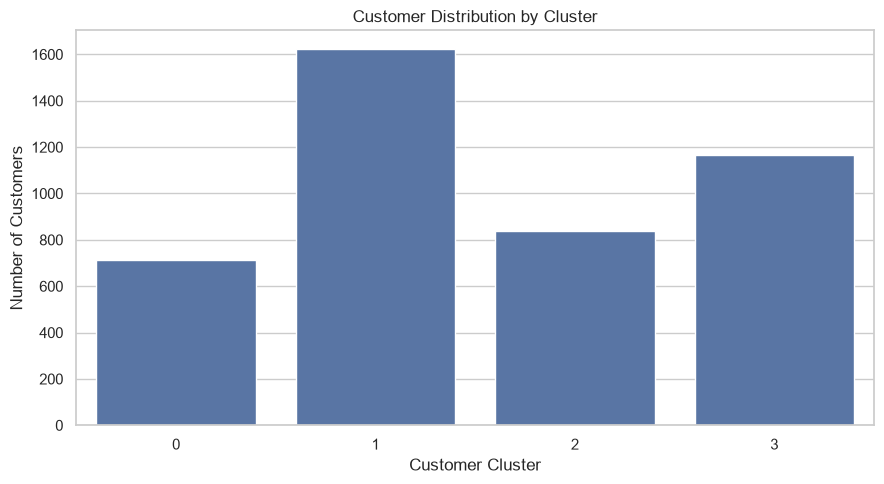

Customer cluster distribution chart saved successfully.


In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare the cluster counts
cluster_counts = (
    rfm_segmented["Cluster"]
    .value_counts()
    .sort_index()
)

# Create the bar chart
plt.figure(figsize=(9, 5))

sns.barplot(
    x=cluster_counts.index.astype(str),
    y=cluster_counts.values
)

plt.title("Customer Distribution by Cluster")
plt.xlabel("Customer Cluster")
plt.ylabel("Number of Customers")
plt.tight_layout()

# Save the chart
plt.savefig(
    "../images/customer_cluster_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Customer cluster distribution chart saved successfully.")

## Business Interpretation of Customer Segments

The four customer clusters are assigned descriptive labels based on their average Recency, Frequency, and Monetary values.

These labels help translate the clustering results into actionable customer relationship and marketing strategies.

In [40]:
# Define business-friendly cluster names

cluster_names = {
    0: "High-Value Loyal Customers",
    1: "At-Risk Customers",
    2: "Recent Low-Spending Customers",
    3: "Regular Customers with Growth Potential"
}

# Create a copy of the segmented dataset
rfm_segmented["Segment"] = (
    rfm_segmented["Cluster"].map(cluster_names)
)

# Display sample customer records
print("Customer Segments with Business Labels:")

display(
    rfm_segmented[
        [
            "CustomerID",
            "Recency",
            "Frequency",
            "Monetary",
            "Cluster",
            "Segment"
        ]
    ].head(10)
)

# Summarize the number of customers in each segment
print("\nCustomer Segment Summary:")

display(
    rfm_segmented["Segment"]
    .value_counts()
    .rename_axis("Segment")
    .reset_index(name="Customer_Count")
)

Customer Segments with Business Labels:


,CustomerID,Recency,Frequency,Monetary,Cluster,Segment
0,12346,326,1,77183.60,3,Regular Customers with Growth Potential
1,12347,2,7,4310.00,0,High-Value Loyal Customers
2,12348,75,4,1797.24,3,Regular Customers with Growth Potential
3,12349,19,1,1757.55,2,Recent Low-Spending Customers
4,12350,310,1,334.40,1,At-Risk Customers
5,12352,36,8,2506.04,3,Regular Customers with Growth Potential
6,12353,204,1,89.00,1,At-Risk Customers
7,12354,232,1,1079.40,1,At-Risk Customers
8,12355,214,1,459.40,1,At-Risk Customers
9,12356,23,3,2811.43,3,Regular Customers with Growth Potential



Customer Segment Summary:


,Segment,Customer_Count
0,At-Risk Customers,1622
1,Regular Customers with Growth Potential,1166
2,Recent Low-Spending Customers,837
3,High-Value Loyal Customers,713


## Average Monetary Value by Customer Segment

This visualization compares average customer revenue across the four segments.

It helps identify the customer groups that contribute the highest average monetary value.

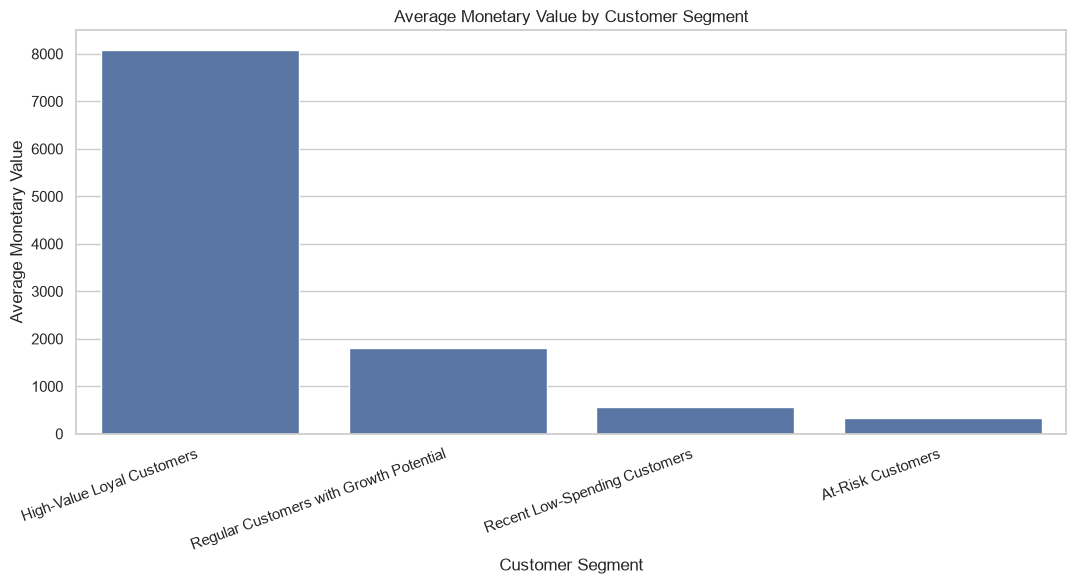

Average monetary value chart saved successfully.


In [41]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate average monetary value by segment
monetary_by_segment = (
    rfm_segmented
    .groupby("Segment")["Monetary"]
    .mean()
    .sort_values(ascending=False)
)

# Create the chart
plt.figure(figsize=(11, 6))

sns.barplot(
    x=monetary_by_segment.index,
    y=monetary_by_segment.values
)

plt.title("Average Monetary Value by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Monetary Value")
plt.xticks(rotation=20, ha="right")

plt.tight_layout()

# Save the chart in the images folder
plt.savefig(
    "../images/average_monetary_by_segment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Average monetary value chart saved successfully.")

## RFM Comparison Across Customer Segments

This section compares the average Recency, Frequency, and Monetary values
across the four customer segments.

The comparison helps identify differences in purchasing behavior,
purchase frequency, and customer value.

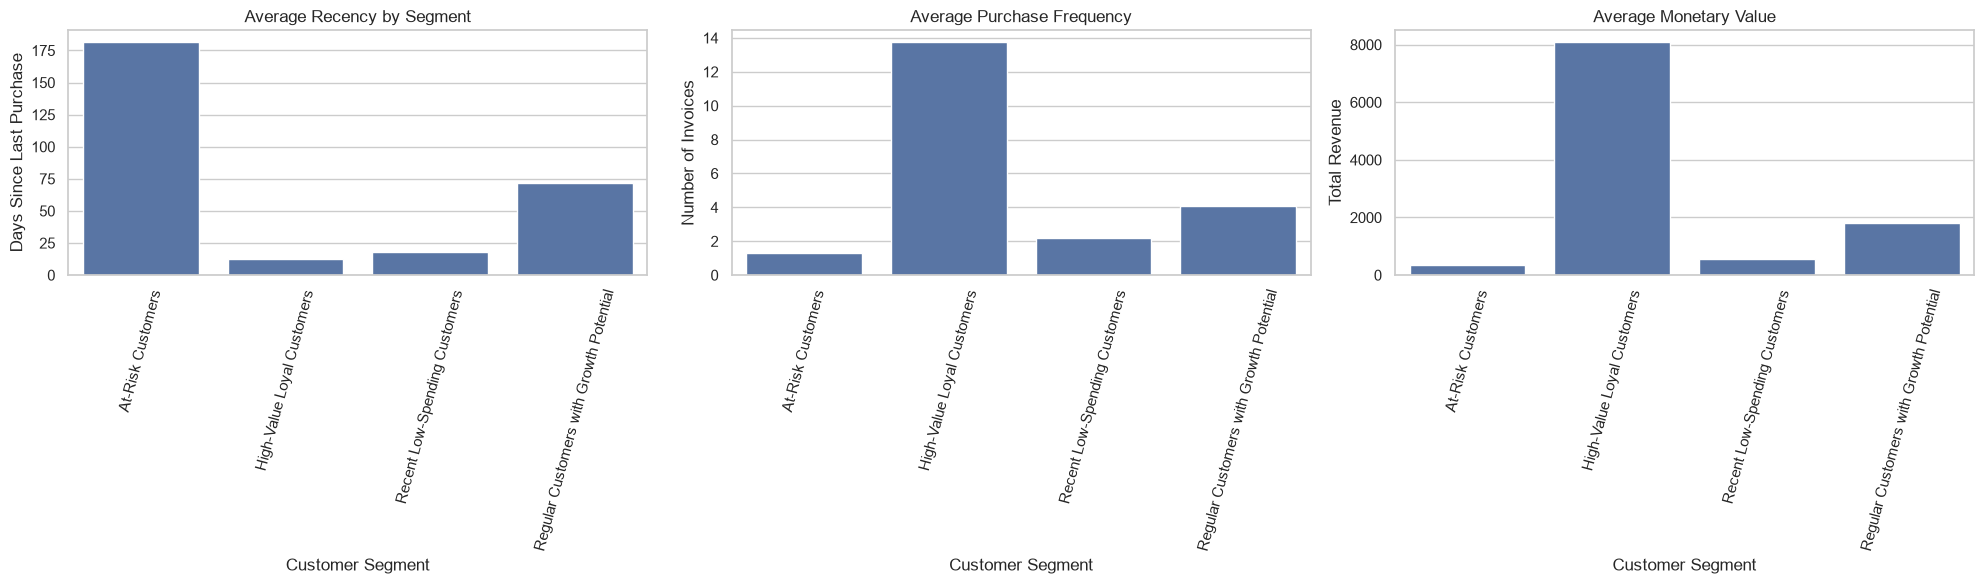

RFM comparison chart saved successfully.


In [42]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate average RFM metrics for each segment
rfm_comparison = (
    rfm_segmented
    .groupby("Segment")[["Recency", "Frequency", "Monetary"]]
    .mean()
    .reset_index()
)

# Create three separate charts
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

sns.barplot(
    data=rfm_comparison,
    x="Segment",
    y="Recency",
    ax=axes[0]
)

axes[0].set_title("Average Recency by Segment")
axes[0].set_xlabel("Customer Segment")
axes[0].set_ylabel("Days Since Last Purchase")
axes[0].tick_params(axis="x", rotation=75)

sns.barplot(
    data=rfm_comparison,
    x="Segment",
    y="Frequency",
    ax=axes[1]
)

axes[1].set_title("Average Purchase Frequency")
axes[1].set_xlabel("Customer Segment")
axes[1].set_ylabel("Number of Invoices")
axes[1].tick_params(axis="x", rotation=75)

sns.barplot(
    data=rfm_comparison,
    x="Segment",
    y="Monetary",
    ax=axes[2]
)

axes[2].set_title("Average Monetary Value")
axes[2].set_xlabel("Customer Segment")
axes[2].set_ylabel("Total Revenue")
axes[2].tick_params(axis="x", rotation=75)

plt.tight_layout()

# Save the visualization
plt.savefig(
    "../images/rfm_comparison_by_segment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("RFM comparison chart saved successfully.")

## Export Final Customer Segmentation Dataset

The final dataset contains customer-level RFM metrics, assigned cluster
numbers, and descriptive customer segment labels.

This dataset can be used for further analysis and business reporting.

In [43]:
from pathlib import Path

# Create the output directory
output_dir = Path("../processed")
output_dir.mkdir(parents=True, exist_ok=True)

# Select the final columns
final_columns = [
    "CustomerID",
    "Recency",
    "Frequency",
    "Monetary",
    "Cluster",
    "Segment"
]

# Create the final dataset
final_customer_data = rfm_segmented[final_columns].copy()

# Export to CSV
output_file = output_dir / "customer_segmentation_results.csv"

final_customer_data.to_csv(output_file, index=False)

print("Customer segmentation dataset exported successfully.")
print("File location:", output_file.resolve())
print("Dataset shape:", final_customer_data.shape)

display(final_customer_data.head())

Customer segmentation dataset exported successfully.
File location: C:\Users\RAM CHOUDHARY\Desktop\Oasis_Customer_Segmentation\processed\customer_segmentation_results.csv
Dataset shape: (4338, 6)


,CustomerID,Recency,Frequency,Monetary,Cluster,Segment
0,12346,326,1,77183.60,3,Regular Customers with Growth Potential
1,12347,2,7,4310.00,0,High-Value Loyal Customers
2,12348,75,4,1797.24,3,Regular Customers with Growth Potential
3,12349,19,1,1757.55,2,Recent Low-Spending Customers
4,12350,310,1,334.40,1,At-Risk Customers


## Final Business Insights and Recommendations

### 1. High-Value Loyal Customers

These customers purchase frequently, have purchased recently, and
generate the highest average monetary value.

**Business Recommendation:**
- Introduce exclusive loyalty rewards.
- Offer personalized product recommendations.
- Provide early access to new products.
- Encourage referrals and repeat purchases.

### 2. At-Risk Customers

This is the largest customer segment. These customers have not purchased
recently and have low average purchase frequency and monetary value.

**Business Recommendation:**
- Launch targeted re-engagement campaigns.
- Send personalized offers based on previous purchases.
- Use email reminders to encourage repeat purchases.
- Monitor campaign response and customer reactivation rates.

### 3. Recent Low-Spending Customers

These customers have purchased relatively recently but have lower
purchase frequency and monetary value.

**Business Recommendation:**
- Offer first-repeat-purchase incentives.
- Recommend complementary products.
- Create product bundles to encourage additional purchases.
- Track conversion into regular customers.

### 4. Regular Customers with Growth Potential

These customers demonstrate moderate purchasing activity and
contribute meaningful revenue.

**Business Recommendation:**
- Introduce tiered loyalty programs.
- Encourage more frequent purchases.
- Recommend higher-value or complementary products.
- Identify customers who could become high-value loyal customers.

### Overall Business Conclusion

RFM analysis and K-Means clustering help identify distinct customer
groups based on purchasing behavior.

The results can support targeted marketing, customer retention,
loyalty programs, and customer lifetime value improvement.

Future campaigns should be evaluated using measurable business KPIs,
including repeat purchase rate, customer reactivation rate, campaign
conversion rate, and revenue per customer.

In [44]:
# Validate the final customer segmentation dataset

print("Dataset shape:", final_customer_data.shape)

print("\nMissing values:")
print(final_customer_data.isnull().sum())

print("\nDuplicate customer IDs:")
print(final_customer_data["CustomerID"].duplicated().sum())

print("\nUnique customer segments:")
print(final_customer_data["Segment"].unique())

print("\nCustomer count by segment:")
print(final_customer_data["Segment"].value_counts())

print("\nCluster count:")
print(final_customer_data["Cluster"].nunique())

# Verify that each customer has one segment
assert final_customer_data["CustomerID"].is_unique

print("\nValidation completed successfully.")

Dataset shape: (4338, 6)

Missing values:
CustomerID    0
Recency       0
Frequency     0
Monetary      0
Cluster       0
Segment       0
dtype: int64

Duplicate customer IDs:
0

Unique customer segments:
<StringArray>
['Regular Customers with Growth Potential',
              'High-Value Loyal Customers',
           'Recent Low-Spending Customers',
                       'At-Risk Customers']
Length: 4, dtype: str

Customer count by segment:
Segment
At-Risk Customers                          1622
Regular Customers with Growth Potential    1166
Recent Low-Spending Customers               837
High-Value Loyal Customers                  713
Name: count, dtype: int64

Cluster count:
4

Validation completed successfully.
